In [614]:
#%%
import math
import numpy as np

import inspect
import importlib

import scipy.interpolate
from scipy import stats
from scipy.stats import norm

import matplotlib
from matplotlib import pyplot as plt
import matplotlib.pyplot as plt
from matplotlib import ticker, cm
from matplotlib import patches as mpatches
from matplotlib.ticker import FuncFormatter
from matplotlib.collections import LineCollection
from matplotlib.colors import LinearSegmentedColormap, ListedColormap
import matplotlib.lines as mlines
from matplotlib import colormaps

import seaborn as sns


plt.rcParams['figure.facecolor'] = 'white'
plt.rcParams['mathtext.fontset'] = 'stix'
plt.rcParams['font.family'] = 'STIXGeneral'
plt.rcParams['font.size'] = 16

import plotly.graph_objects as go
import plotly.express as px
import plotly.io as pio
from plotly.offline import plot
pio.renderers.default = "svg"

import sys
import os
parent_directory = os.path.dirname(os.getcwd())
sys.path.append(parent_directory)
#sys.path.append(os.path.dirname(parent_directory))
#sys.path.append(os.path.dirname(os.path.dirname(parent_directory)))

from IoT_node_models.Energy_model                        import *
from IoT_node_models.Energy_model.Wireless_communication import *
from IoT_node_models.Hardware_Modules                    import *
from IoT_node_models.Analysis                            import *

from fft_architecture_exploration                        import *

path_to_save_svg = "Saved_Data"


rng = np.random.default_rng(42)

In [615]:
fontsize        = 14
fontsize_perc   = 12
fontsize_ytick  = 12
fontsize_legend = 8

matplotlib.rcParams.update({'font.size': fontsize})
matplotlib.rcParams['lines.linewidth'] = 1.5
matplotlib.rcParams['xtick.major.size'] = 5
matplotlib.rcParams['xtick.major.width'] = 1
matplotlib.rcParams['ytick.major.size'] = 5
matplotlib.rcParams['ytick.major.width'] = 1
matplotlib.rc('axes', linewidth=1)


matplotlib.rcParams["font.family"] =  'Montserrat'
matplotlib.rcParams['figure.facecolor'] = 'white'
matplotlib.rcParams['svg.fonttype'] = 'none'

In [616]:
dictColor = {"DeepBlue"     :"#095256",
             "LightBlue"    :"#01a7c2",
             "UnitedBlue"   :"#6290c8",
             "CerulBlue"    :"#6096ba",
             "Green"        :"#44af69",
             "LightRed"     :"#f8333c",
             "DeepRed"      :"#a22c29",
             "Orange"       :"#fcab10",
             "Sandy"        :"#fc9e4F",
             "Olivine"      :"#9ab87a",
             "CarolinaBlue" :"#009DDC"}
listColor = list(dictColor.values())

In [617]:

import matplotlib.colors as mcolors

# Define base colors for each row
base_colors = {
    'red': '#f8333c',      # LightRed as base
    'blue': "#64ABD4",     # DeepBlue as base  
    'green': '#44af69',    # Green as base
    'orange': '#fcab10',   # Orange as base
    'purple': '#800080'    # Standard purple as base
}

# Create 10 nuances for each color by varying lightness
color_array = np.zeros((5, 10), dtype=object)

for i, (color_name, base_hex) in enumerate(base_colors.items()):
    base_rgb = mcolors.hex2color(base_hex)
    for j in range(10):
        # Create lighter/darker variations by scaling RGB values
        # Use a non-linear scaling for better visual distribution
        scale = 0.5 + 0.5 * (j / 9) ** 0.7  # 0.5 to 1.0 with curve
        if color_name == 'purple':
            # For purple, create a nice gradient from dark to light
            lightness = j / 9.0  # 0 to 1
            if j < 5:
                # Dark to medium purples
                r = 0.5 + 0.3 * (j / 4.0)
                b = 0.5 + 0.3 * (j / 4.0)
                g = 0.0 + 0.2 * (j / 4.0)
            else:
                # Medium to light purples
                r = 0.8 + 0.2 * ((j - 5) / 4.0)
                b = 0.8 + 0.2 * ((j - 5) / 4.0)
                g = 0.4 + 0.4 * ((j - 5) / 4.0)
            color_array[i, j] = mcolors.rgb2hex((r, g, b))
        else:
            # For other colors, scale from darker to lighter
            if j < 5:
                # Darker variations (scale down)
                scaled_rgb = tuple(max(0, min(1, c * (0.4 + 0.6 * (j / 4.0)))) for c in base_rgb)
            else:
                # Lighter variations (scale up)
                scaled_rgb = tuple(max(0, min(1, c * (1.0 + 0.6 * ((j - 5) / 4.0)))) for c in base_rgb)
            color_array[i, j] = mcolors.rgb2hex(scaled_rgb)

# Rename rows for clarity
color_names = ['red', 'blue', 'green', 'orange', 'purple']

In [618]:



importlib.reload(sys.modules['fft_architecture_exploration'])
from fft_architecture_exploration import * 

In [619]:
analysis_Mem_type  = np.array([1]) # 0: 1xSP SRAM,   1: 2xSP SRAM, 2: 2xHalf-size SP SRAM,  3: 1xDP SRAM
analysis_nMem_type = len(analysis_Mem_type)

baseline_area    = pipe_theor_Area[0,analysis_Mem_type]
add_baseline_area = False

baseline_techNode= 65 #10
baseline_energy  = pipe_theor_Energy [0,analysis_Mem_type]
baseline_latency = pipe_theor_Latency[0,analysis_Mem_type]
baseline_power   = baseline_energy / baseline_latency

area_overlap = 0#0.095

beta = 1.0

In [620]:
analysis_Mem_type  = np.array([1]) # 0: 1xSP SRAM,   1: 2xSP SRAM, 2: 2xHalf-size SP SRAM,  3: 1xDP SRAM
analysis_nMem_type = len(analysis_Mem_type)

#baseline_area    = [10/((90/65)**2)]
baseline_area    = 0.5
add_baseline_area = True

baseline_techNode= 65 #10
baseline_energy  = nFFT* 5.7e-9
baseline_latency = nFFT* 80
baseline_power   = baseline_energy / baseline_latency

area_overlap = 0#0.095

beta = 1

In [621]:
arch_Dim = arch_Dim

In [622]:
# ----------------------------------------------------------------------
#           RATIO
# ----------------------------------------------------------------------


para_theor_Speedup        = baseline_latency        / para_theor_Latency                                
para_theor_Power          = para_theor_Energy       / para_theor_Latency
   
pipePara_theor_Speedup    = baseline_latency            / pipePara_theor_Latency                                
pipePara_theor_Power      = pipePara_theor_Energy       / pipePara_theor_Latency 

pipe_theor_Speedup        = baseline_latency        / pipe_theor_Latency                                
pipe_theor_Power          = pipe_theor_Energy       / pipe_theor_Latency

# ----------------------------------------------------------------------

theor_Area             = np.array([pipe_theor_Area         ,  para_theor_Area     ,  pipePara_theor_Area]) - area_overlap
theor_Latency          = np.array([pipe_theor_Latency      ,  para_theor_Latency  ,  pipePara_theor_Latency])
theor_Energy           = np.array([pipe_theor_Energy       ,  para_theor_Energy   ,  pipePara_theor_Energy])
theor_Speedup          = np.array([pipe_theor_Speedup      ,  para_theor_Speedup  ,  pipePara_theor_Speedup])                              
theor_Power            = np.array([pipe_theor_Power        ,  para_theor_Power    ,  pipePara_theor_Power]) 

# ----------------------------------------------------------------------

para_theor_area_delta    = (para_theor_Area[:,:,np.newaxis]+baseline_area*add_baseline_area - area_overlap)    - baseline_area
para_theor_area_ratio    = (para_theor_Area[:,:,np.newaxis]+baseline_area*add_baseline_area - area_overlap)    / baseline_area
para_theor_power_ratio   = para_theor_Power   / baseline_power
para_theor_energy_ratio  = para_theor_Energy  / baseline_energy
para_theor_latency_ratio = para_theor_Latency / baseline_latency
para_theor_speedup_ratio = 1/(para_theor_latency_ratio)


# ----------------------------------------------------------------------
pipe_theor_area_delta    = (pipe_theor_Area[:,:,np.newaxis]+baseline_area*add_baseline_area - area_overlap)    - baseline_area
pipe_theor_area_ratio    = (pipe_theor_Area[:,:,np.newaxis]+baseline_area*add_baseline_area - area_overlap)    / baseline_area
pipe_theor_power_ratio   = pipe_theor_Power   / baseline_power
pipe_theor_energy_ratio  = pipe_theor_Energy  / baseline_energy
pipe_theor_latency_ratio = pipe_theor_Latency / baseline_latency
pipe_theor_speedup_ratio = 1/(pipe_theor_latency_ratio)


# ----------------------------------------------------------------------
pipePara_theor_area_delta    = (pipePara_theor_Area[:,:,np.newaxis]+baseline_area*add_baseline_area - area_overlap)    - baseline_area
pipePara_theor_area_ratio    = (pipePara_theor_Area[:,:,np.newaxis]+baseline_area*add_baseline_area - area_overlap)    / baseline_area
pipePara_theor_power_ratio   = pipePara_theor_Power   / baseline_power
pipePara_theor_energy_ratio  = pipePara_theor_Energy  / baseline_energy
pipePara_theor_latency_ratio = pipePara_theor_Latency / baseline_latency
pipePara_theor_speedup_ratio = 1/(pipePara_theor_latency_ratio)

# ----------------------------------------------------------------------


theor_area_ratio        = np.array([pipe_theor_area_ratio       , para_theor_area_ratio    , pipePara_theor_area_ratio])  
theor_area_delta        = np.array([pipe_theor_area_delta       , para_theor_area_delta    , pipePara_theor_area_delta])  
theor_power_ratio       = np.array([pipe_theor_power_ratio      , para_theor_power_ratio   , pipePara_theor_power_ratio])
theor_energy_ratio      = np.array([pipe_theor_energy_ratio     , para_theor_energy_ratio  , pipePara_theor_energy_ratio])
theor_latency_ratio     = np.array([pipe_theor_latency_ratio    , para_theor_latency_ratio , pipePara_theor_latency_ratio])                              
theor_speedup_ratio     = np.array([pipe_theor_speedup_ratio    , para_theor_speedup_ratio , pipePara_theor_speedup_ratio]) 

In [623]:
#----------------------------------------------------------------------------------

our_Area           = np.array([0.119    , 0.123    , 0.129    , 0.141    ] ) 
our_NFFT           = np.array([4096     , 4096     , 4096     , 4096     ] )                 
our_Latency_pFFT   = np.array([98423    , 49250    , 32883    , 24723    ] )               
our_Energy_pFFT    = np.array([3388.9   , 1922.4   , 1434.1   , 1197.6    ] ) *1e-9 

our_Latency        = our_Latency_pFFT   
our_Energy         = our_Energy_pFFT       
our_Speedup        = baseline_latency / our_Latency                                
our_Power          = our_Energy       / our_Latency  

our_area_ratio    = (our_Area[:,np.newaxis]+baseline_area*add_baseline_area)    / baseline_area
our_power_ratio   = our_Power   / baseline_power
our_energy_ratio  = our_Energy  / baseline_energy
our_latency_ratio = our_Latency / baseline_latency
our_speedup_ratio = 1/(our_latency_ratio)

#----------------------------------------------------------------------------------
soA_name          =           [ "Pereira 22" , "Berta. 21 ", "Gonz. 24",  "Yang 21", "Mahdavi 19", "Shih 18", "Shih 18", "Tian 19"  , "Paul 25"  , "Zhang 25" ,  "Liu 18"   ]         #"Deng 23"
soA_type          =           [ "Memory-b"   , "Memory-b"  , "Memory-b",  "Pipel." , "Pipel."    , "Pipel." , "Pipel." , "Memory-b" , "Memory-b" , "Memory-b" ,  "Memory-b" ]         #"Pipel." 
soA_techNode      =           [    65        , 22          , 22        ,  65       , 28          , 40       , 40       ,65          , 65         , 40         ,     65      ]         #40
soa_Area_FFT       = np.array([    0.185     , 0.185       , 1.08      ,  1.83     , 0.57        , 1.09     , 1.25     ,0.84        , 3.8        , 1.11       ,    1.67     ] )       #0.48                        
soa_NFFT           = np.array([    256       , 1024        , 1024      ,  2048     , 2048        , 2048     , 4096     ,4096        , 4096       , 4096       ,    4096     ] )       #1024                       
soa_Latency_pFFT   = np.array([    1025      , 3005        , 1320      ,  2048     , 1200        , 2048     , 4096     ,5120        , 605        , 2259       ,    768      ] )       #245                         
soa_Energy_pFFT    = np.array([    187.23    , 1054.78     , 297.92    ,  260.31   , 600.82      , 541.60   , 1658.43  ,599.04      , 495.67     , 1221.50    ,   240.98    ] ) *1e-9 #22.94      

soa_Area           = scale_area    (area= soa_Area_FFT,        nfft_ref = 4096, nfft = soa_NFFT, acc_type =soA_type)    
soa_Latency        = scale_latency (latency= soa_Latency_pFFT, nfft_ref = 4096, nfft = soa_NFFT, acc_type =soA_type)                      
soa_Energy         = soa_Energy_pFFT  * (4096*12/(soa_NFFT*np.log2(soa_NFFT)))     
 
soa_Speedup        = baseline_latency / soa_Latency                               
soa_Power          = soa_Energy       / soa_Latency  

soa_area_ratio    = (soa_Area[:,np.newaxis]+baseline_area*add_baseline_area)    / baseline_area
soa_power_ratio   = soa_Power   / baseline_power
soa_energy_ratio  = soa_Energy  / baseline_energy
soa_latency_ratio = soa_Latency / baseline_latency
soa_speedup_ratio = 1/(soa_latency_ratio)

#----------------------------------------------------------------------------------
soA_pt_name          =           [ "Liu 18"   ]   
soA_pt_type          =           [ "Memory-b" ]   
soA_pt_techNode       =          [    65      ] 
soa_pt_Area_FFT       = np.array([   1.67     ] ) 
soa_pt_NFFT           = np.array([   4096     ] ) 
soa_pt_Latency_pFFT   = np.array([   768      ] ) 
soa_pt_Energy_pFFT    = np.array([  240.98    ] ) *1e-9

soa_pt_Area           = scale_area    (area= soa_pt_Area_FFT,        nfft_ref = 4096, nfft = soa_pt_NFFT, acc_type =soA_pt_type)    
soa_pt_Latency        = scale_latency (latency= soa_pt_Latency_pFFT, nfft_ref = 4096, nfft = soa_pt_NFFT, acc_type =soA_pt_type)                      
soa_pt_Energy         = soa_pt_Energy_pFFT  * (4096*12/(soa_pt_NFFT*np.log2(soa_pt_NFFT)))     
 
soa_pt_Speedup        = baseline_latency / soa_pt_Latency                               
soa_pt_Power          = soa_pt_Energy    / soa_pt_Latency  

soa_pt_area_ratio    = (soa_pt_Area[:,np.newaxis]+baseline_area*add_baseline_area)    / baseline_area
soa_pt_power_ratio   = soa_pt_Power   / baseline_power
soa_pt_energy_ratio  = soa_pt_Energy  / baseline_energy
soa_pt_latency_ratio = soa_pt_Latency / baseline_latency
soa_pt_speedup_ratio = 1/(soa_pt_latency_ratio)



In [624]:
soa_only_last_one =True

In [625]:
use_delta = False

if use_delta:
    def asi_function(alpha = 0.5, base_area  = 1, delta_area=1, base_energy = 1 ,new_energy=1,speedup=1):
        return (-(delta_area*base_energy/(base_area*new_energy*alpha)) + (base_energy/new_energy))/speedup

    def wfi_function(alpha = 0.5, base_area  = 1, delta_area=1, base_energy = 1 ,new_energy=1):
        return (-(delta_area*base_energy/(base_area*new_energy*alpha)) + (base_energy/new_energy))

else:
    def asi_function(alpha = 0.5, area_ratio  = 1, energy_ratio = 1 ,speedup=1):
        return (1+alpha-area_ratio)/(alpha*energy_ratio*speedup)

    def wfi_function(alpha = 0.5, area_ratio  = 1, energy_ratio = 1):
        return (1+alpha-area_ratio)/(alpha*energy_ratio)

In [626]:
alpha_s_low  = -3
alpha_s_high = 3
alpha_n = 100
alpha_studied = np.logspace(alpha_s_low, alpha_s_high, alpha_n,endpoint=True)

# ----------------------------------------------------------------------
# 2a. DERIVE RATIOS 
# ----------------------------------------------------------------------

theor_asi_res     = np.zeros((len(alpha_studied),3,arch_Dim,analysis_nMem_type))
theor_ncf_res     = np.zeros((len(alpha_studied),3,arch_Dim,analysis_nMem_type,2))
for k in range(3):
    for i in range(arch_Dim):
        for d, j in enumerate(analysis_Mem_type):
            if use_delta:
                theor_asi_res[:,k,i,d]  = asi_function(alpha = alpha_studied, base_area  = baseline_area, delta_area=theor_area_delta[k,i,j]+baseline_area*add_baseline_area, base_energy = baseline_energy ,new_energy=theor_Energy[k,i,j],speedup=theor_speedup_ratio[k,i,j])                      
                theor_ncf_res[:,k,i,d,0]= (theor_area_delta[k,i,j])/baseline_area +  (alpha_studied * (                           theor_Energy[k,i,j] - baseline_energy) )/baseline_energy
                theor_ncf_res[:,k,i,d,1]= (theor_area_delta[k,i,j])/baseline_area +  (alpha_studied * (theor_speedup_ratio[k,i,j]*theor_Energy[k,i,j] - baseline_energy) )/baseline_energy
            else:  
                theor_asi_res[:,k,i,d]  = asi_function (alpha=alpha_studied, area_ratio=theor_area_ratio[k,i,j], energy_ratio=theor_energy_ratio[k,i,j],speedup=theor_speedup_ratio[k,i,j])        
                theor_ncf_res[:,k,i,d,0]= (theor_area_ratio[k,i,j]) +  (alpha_studied * (                           theor_energy_ratio[k,i,j]))
                theor_ncf_res[:,k,i,d,1]= (theor_area_ratio[k,i,j]) +  (alpha_studied * (theor_speedup_ratio[k,i,j]*theor_energy_ratio[k,i,j]))
    
            print(f"THEOR {k}{j},{i}:  area={theor_Area[k,i,j]:.4f},  power_ratio={theor_power_ratio[k,i,j]:.2f}, energy_ratio={theor_energy_ratio[k,i,j]:.2f}, speedup={theor_speedup_ratio[k,i,j]:.2e}, ncf={theor_ncf_res[0,k,i,d,0]:.2e}")


theor_ncf_test     = np.zeros((len(alpha_studied),3,arch_Dim,analysis_nMem_type))
for k in range(3):
    for i in range(arch_Dim):
        for d, j in enumerate(analysis_Mem_type):
            if use_delta:
                theor_ncf_test[:,k,i,d]= wfi_function(alpha = alpha_studied, base_area  = baseline_area, delta_area=theor_area_delta[k,i,j], base_energy = baseline_energy ,new_energy=theor_Energy[k,i,j])
            else:
                theor_ncf_test[:,k,i,d]= wfi_function (alpha=alpha_studied, area_ratio=theor_area_ratio[k,i,j], energy_ratio=theor_energy_ratio[k,i,j])   

    

THEOR 01,0:  area=0.1951,  power_ratio=0.80, energy_ratio=0.12, speedup=6.67e+00, ncf=1.39e+00
THEOR 01,1:  area=0.2013,  power_ratio=0.91, energy_ratio=0.07, speedup=1.33e+01, ncf=1.40e+00
THEOR 01,2:  area=0.2074,  power_ratio=1.02, energy_ratio=0.05, speedup=2.00e+01, ncf=1.41e+00
THEOR 01,3:  area=0.2135,  power_ratio=1.14, energy_ratio=0.04, speedup=2.67e+01, ncf=1.43e+00
THEOR 01,4:  area=0.2196,  power_ratio=1.25, energy_ratio=0.04, speedup=3.33e+01, ncf=1.44e+00
THEOR 11,0:  area=0.1951,  power_ratio=0.80, energy_ratio=0.12, speedup=6.67e+00, ncf=1.39e+00
THEOR 11,1:  area=0.2375,  power_ratio=1.23, energy_ratio=0.09, speedup=1.33e+01, ncf=1.48e+00
THEOR 11,2:  area=0.2861,  power_ratio=2.00, energy_ratio=0.07, speedup=2.67e+01, ncf=1.57e+00
THEOR 11,3:  area=0.3722,  power_ratio=3.61, energy_ratio=0.07, speedup=5.33e+01, ncf=1.74e+00
THEOR 11,4:  area=0.5845,  power_ratio=3.97, energy_ratio=0.04, speedup=1.07e+02, ncf=2.17e+00
THEOR 21,0:  area=0.1951,  power_ratio=0.80, energ

Text(0, 0.5, 'EAP')

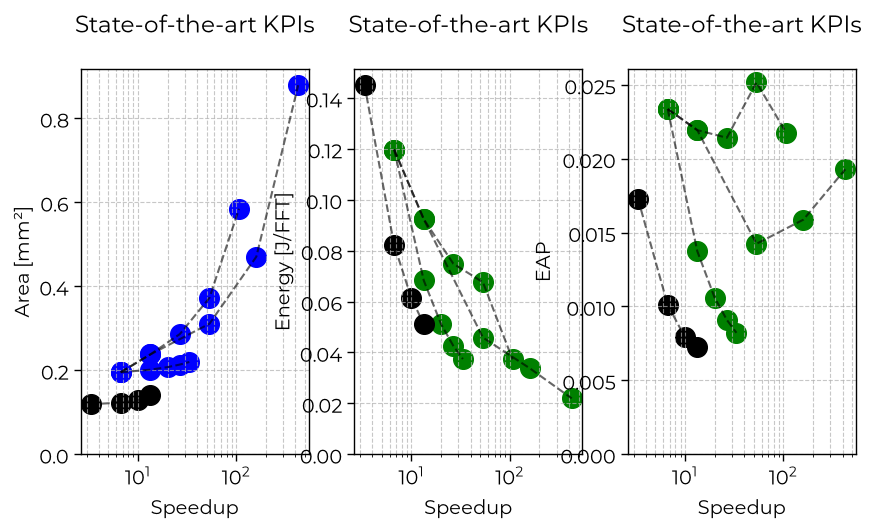

In [627]:
alpha_not_fft_size   = 0.3
plot_scaled_fft_size = 1

markersize = 200

soa_patch      = mlines.Line2D([], [], color='gray', marker="s", markersize=8, linewidth=0, label='State-of-the-Art')
soa_pt_patch   = mlines.Line2D([], [], color='gray', marker="<", markersize=8, linewidth=0, label='Liu 2018')
model_patch    = mlines.Line2D([], [], color='gray', marker="o", markersize=8, linewidth=0, label='FFT HW Acc. Model')
our_patch      = mlines.Line2D([], [], color='gray', marker="o", markersize=8, linewidth=0, label='Our DWIFgn')

nPlot = 3
fig, ax = plt.subplots(1,nPlot, figsize=(10, 5), squeeze=False)


#sc = ax[0,0].scatter(   1,1, s=markersize ,  alpha=1, marker = 'o', color="black") 

for d, i in enumerate(analysis_Mem_type):
    for j in range(3):
        ax[0,0].plot(            theor_speedup_ratio[j,:,i], theor_Area[j,:,i], color = 'black', alpha=0.6, linestyle ='--')
        sc = ax[0,0].scatter(    theor_speedup_ratio[j,:,i], theor_Area[j,:,i], s=markersize ,  alpha=1, marker = 'o', color = 'blue')

        
        ax[0,1].plot(           theor_speedup_ratio[j,:,i],  theor_energy_ratio[j,:,i], color = 'black', alpha=0.6, linestyle ='--')
        sc = ax[0,1].scatter(   theor_speedup_ratio[j,:,i],  theor_energy_ratio[j,:,i], s=markersize ,  alpha=1, marker = 'o', color = 'green')

        
        ax[0,2].plot(           theor_speedup_ratio[j,:,i],  theor_Area[j,:,i]*theor_energy_ratio[j,:,i], color = 'black', alpha=0.6, linestyle ='--')
        sc = ax[0,2].scatter(   theor_speedup_ratio[j,:,i],  theor_Area[j,:,i]*theor_energy_ratio[j,:,i], s=markersize ,  alpha=1, marker = 'o', color = 'green')
        
ax[0,0].plot(           our_speedup_ratio,  our_Area, color = 'black', alpha=0.6, linestyle ='--')
sc = ax[0,0].scatter(   our_speedup_ratio,  our_Area, s=markersize ,  alpha=1, marker = 'o', color = 'black')
ax[0,1].plot(           our_speedup_ratio,  our_energy_ratio, color = 'black', alpha=0.6, linestyle ='--')
sc = ax[0,1].scatter(   our_speedup_ratio,  our_energy_ratio, s=markersize ,  alpha=1, marker = 'o', color = 'black')
ax[0,2].plot(           our_speedup_ratio,  our_Area*our_energy_ratio, color = 'black', alpha=0.6, linestyle ='--')
sc = ax[0,2].scatter(   our_speedup_ratio,  our_Area*our_energy_ratio, s=markersize ,  alpha=1, marker = 'o', color = 'black')



#ax.legend()
#ax.legend(handles=[soa_patch, soa_pt_patch, model_patch, our_patch],fontsize = 13)

for i in range(nPlot):
    ax[0,i].set_ylim([0, None])
    ax[0,i].set_yscale('linear')

    #ax[0,i].set_xlim([0, None])
    ax[0,i].set_xscale('log')

    ax[0,i].grid(True, which='both', linestyle='--', alpha=0.7)
    ax[0,i].set_xlabel('Speedup')
    ax[0,i].set_title('State-of-the-art KPIs\n')

ax[0,0].set_ylabel('Area [mm²]')
ax[0,1].set_ylabel('Energy [J/FFT]')
ax[0,2].set_ylabel('EAP')

Text(0.5, 1.0, 'State-of-the-art KPIs\n')

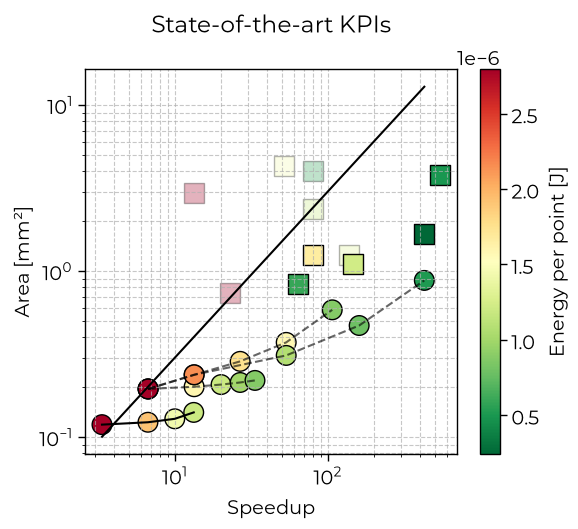

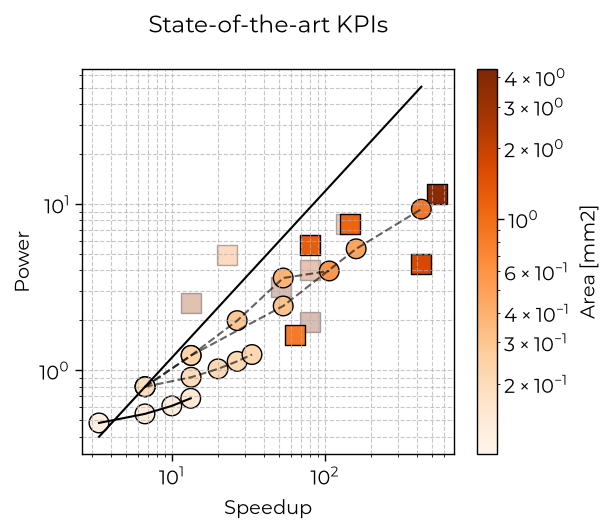

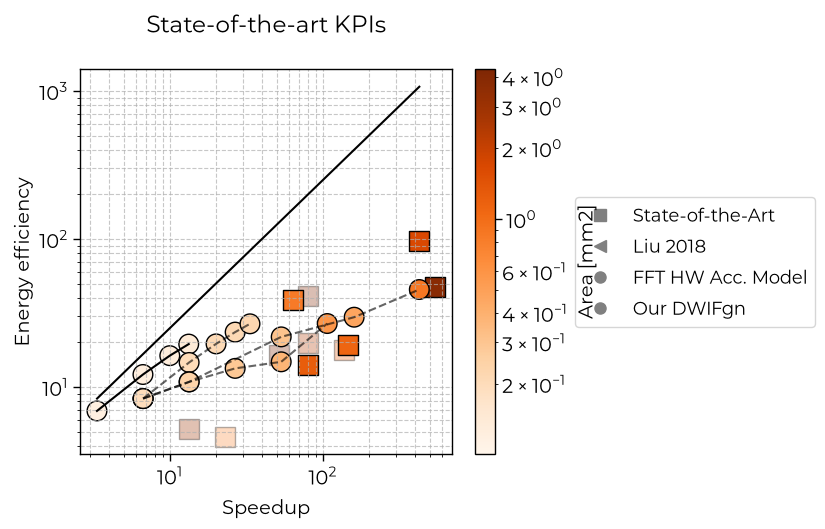

In [628]:
alpha_not_fft_size   = 0.3
plot_scaled_fft_size = 1

markersize = 200

soa_patch      = mlines.Line2D([], [], color='gray', marker="s", markersize=8, linewidth=0, label='State-of-the-Art')
soa_pt_patch   = mlines.Line2D([], [], color='gray', marker="<", markersize=8, linewidth=0, label='Liu 2018')
model_patch    = mlines.Line2D([], [], color='gray', marker="o", markersize=8, linewidth=0, label='FFT HW Acc. Model')
our_patch      = mlines.Line2D([], [], color='gray', marker="o", markersize=8, linewidth=0, label='Our DWIFgn')

fig, ax = plt.subplots(1,1, figsize=(6, 5))


ax.plot([np.min(theor_Speedup) , np.max(soa_pt_speedup_ratio)]   , [np.min(theor_Area), np.min(theor_Area)/np.min(theor_speedup_ratio) * np.max(soa_pt_speedup_ratio)]   , color = "black")    
ax.plot(our_Speedup    , our_Area  , color = "black")
sc = ax.scatter(soa_pt_Speedup, soa_pt_Area, s=markersize , c= soa_pt_Energy,  cmap='RdYlGn_r', vmin =np.min(soa_Energy)   ,vmax = np.max(pipe_theor_Energy),  marker = '<', edgecolors="black",label="Liu 2018"        ,alpha=1               )  #s=soa_pt_Power*4e12
sc = ax.scatter(our_Speedup   , our_Area   , s=markersize , c= our_Energy   ,  cmap='RdYlGn_r', vmin =np.min(soa_Energy)   ,vmax = np.max(pipe_theor_Energy),  marker = 'o', edgecolors="black",label="Our Approach"    ,alpha=1              )  #s=our_Power*4e12   

for i in range(len(soA_techNode)):
    if soa_NFFT[i] == nFFT:
        sc = ax.scatter(soa_Speedup[i]  , soa_Area[i]   , s=markersize , c= soa_Energy[i]   ,  cmap='RdYlGn_r', vmin =np.min(soa_Energy)   ,vmax = np.max(pipe_theor_Energy),  marker = 's', edgecolors="black",label="State-of-the-Art",alpha = 1)  #s=soa_Power*4e12   
    elif (plot_scaled_fft_size==1): 
        sc = ax.scatter(soa_Speedup[i]  , soa_Area[i]   , s=markersize , c= soa_Energy[i]   ,  cmap='RdYlGn_r', vmin =np.min(soa_Energy)   ,vmax = np.max(pipe_theor_Energy),  marker = 's', edgecolors="black",label="State-of-the-Art",alpha = alpha_not_fft_size)  #s=soa_Power*4e12   


for d, i in enumerate(analysis_Mem_type):
    for j in range(3):
        ax.plot(theor_Speedup[j,:,i], theor_Area[j,:,i], color = 'black', alpha=0.6, linestyle ='--')
        sc = ax.scatter(    theor_Speedup[j,:,i],     theor_Area[j,:,i], s=markersize , c=     theor_Energy[j,:,i],  cmap='RdYlGn_r', vmin =np.min(soa_Energy),vmax = np.max(theor_Energy), alpha=1, marker = 'o', edgecolors="black") #  s=    theor_Power[j,:,i]*4e12

fig.colorbar(sc, ax=ax, label='Energy per point [J]', location='right')

#ax.legend()
#ax.legend(handles=[soa_patch, soa_pt_patch, model_patch, our_patch],fontsize = 13)

ax.set_yscale('log')
ax.set_xscale('log')
ax.grid(True, which='both', linestyle='--', alpha=0.7)
ax.set_ylabel('Area [mm²]')
ax.set_xlabel('Speedup')
ax.set_title('State-of-the-art KPIs\n')

######################################################################################################################
fig, ax = plt.subplots(1,1, figsize=(6, 5))

normArea = colors.LogNorm(vmin=theor_Area.min(), vmax=soa_Area.max())

ax.plot([np.min(theor_Speedup) , np.max(soa_pt_speedup_ratio)]   , [np.min(theor_power_ratio), np.min(theor_power_ratio)/np.min(theor_Speedup) * np.max(soa_pt_speedup_ratio)]   , color = "black")    
ax.plot(our_Speedup    , our_power_ratio  , color = "black")        
sc = ax.scatter(soa_pt_Speedup, soa_pt_power_ratio, s=markersize , c= soa_pt_Area,  norm=normArea, cmap='Oranges', marker = '<', edgecolors="black",label="Liu 2018"                                ) # s=soa_pt_Area*2e3
sc = ax.scatter(our_Speedup   , our_power_ratio   , s=markersize , c= our_Area   ,  norm=normArea, cmap='Oranges', marker = 'o', edgecolors="black",label="Our Approach"                            ) # s=our_Area*2e3   

for i in range(len(soA_techNode)):
    if soa_NFFT[i] == nFFT:
        sc = ax.scatter(soa_Speedup[i]   , soa_power_ratio [i]  , s=markersize , c= soa_Area[i]   ,  norm=normArea, cmap='Oranges', marker = 's', edgecolors="black",label="State-of-the-Art", alpha = 1) # s=soa_Area*2e3   
    elif (plot_scaled_fft_size==1): 
        sc = ax.scatter(soa_Speedup[i]   , soa_power_ratio[i]   , s=markersize , c= soa_Area[i]   ,  norm=normArea, cmap='Oranges', marker = 's', edgecolors="black",label="State-of-the-Art", alpha =  alpha_not_fft_size)  #s=soa_Power*4e12   

for i in analysis_Mem_type:
    for j in range(3):
        ax.plot(theor_Speedup[j,:,i], theor_power_ratio[j,:,i], color = 'black', alpha=0.6, linestyle ='--')
        sc = ax.scatter(    theor_Speedup[j,:,i],     theor_power_ratio[j,:,i], s=markersize , c=     theor_Area[j,:,i],  norm=normArea, cmap='Oranges', alpha=1, marker = 'o', edgecolors="black") # s=    theor_Area[j,:,i]*2e3

fig.colorbar(sc, ax=ax, label='Area [mm2]', location='right')

#ax.legend()
#ax.legend(handles=[soa_patch, soa_pt_patch, model_patch, our_patch],fontsize = 13)

ax.set_yscale('log')
ax.set_xscale('log')
ax.grid(True, which='both', linestyle='--', alpha=0.7)
ax.set_ylabel('Power')
ax.set_xlabel('Speedup')
ax.set_title('State-of-the-art KPIs\n')


######################################################################################################################
fig, ax = plt.subplots(1,1, figsize=(6, 5))

ax.plot([np.min(theor_speedup_ratio) , np.max(soa_pt_speedup_ratio)]   , [np.min(1/theor_energy_ratio), np.min(1/theor_energy_ratio)/np.min(theor_speedup_ratio) * np.max(soa_pt_speedup_ratio)]   , color = "black")    
ax.plot(our_Speedup    , 1/our_energy_ratio  , color = "black")
sc = ax.scatter(soa_pt_Speedup, 1/soa_pt_energy_ratio, s = markersize , c= soa_pt_Area ,norm=normArea,  cmap='Oranges',  marker = '<', edgecolors="black", label="Liu 2018"                                ) #s=soa_pt_Area*2e3
sc = ax.scatter(our_Speedup   , 1/our_energy_ratio   , s = markersize , c= our_Area    ,norm=normArea,  cmap='Oranges',  marker = 'o', edgecolors="black", label="Our Approach"                            ) #s=our_Area*2e3   

for i in range(len(soA_techNode)):
    if soa_NFFT[i] == nFFT:
        sc = ax.scatter(soa_Speedup[i]   , 1/soa_energy_ratio[i]   , s = markersize , c= soa_Area[i]    ,norm=normArea,  cmap='Oranges',  marker = 's', edgecolors="black", label="State-of-the-Art", alpha = 1) #s=soa_Area*2e3   
    elif (plot_scaled_fft_size==1): 
       sc = ax.scatter(soa_Speedup[i]   , 1/soa_energy_ratio[i]   , s = markersize , c= soa_Area[i]    ,norm=normArea,  cmap='Oranges',  marker = 's', edgecolors="black", label="State-of-the-Art", alpha = alpha_not_fft_size) #s=soa_Area*2e3   

for i in analysis_Mem_type:
    for j in range(3):
        ax.plot(theor_Speedup[j,:,i], 1/theor_energy_ratio[j,:,i], color = 'black', alpha=0.6, linestyle ='--')
        sc = ax.scatter(    theor_Speedup[j,:,i],     1/theor_energy_ratio[j,:,i], s = markersize ,norm=normArea, c=     theor_Area[j,:,i],  cmap='Oranges',   alpha=1, marker = 'o', edgecolors="black") # s=    theor_Area[j,:,i]*2e3
        
fig.colorbar(sc, ax=ax, label='Area [mm2]', location='right')


#ax.legend()
ax.legend(handles=[soa_patch, soa_pt_patch, model_patch, our_patch],fontsize = 13, loc='right', bbox_to_anchor=(2,0.5) )
ax.set_yscale('log')
ax.set_xscale('log')
ax.grid(True, which='both', linestyle='--', alpha=0.7)
ax.set_ylabel('Energy efficiency')
ax.set_xlabel('Speedup')
ax.set_title('State-of-the-art KPIs\n')

In [653]:

F_p_J_grid = 1.27e-07 #kgCO2/J
F_p_J_batt = 1.16e-05 #kgCO2/J

F_p_mm2 = 0.97/100


cases_array= np.array([
    # Name,               Area, Emb      Carbon In  Lifetime      fs
    [ " Biomed - batt  " ,0.6 , F_p_mm2, F_p_J_batt,    10  ,    3.6e2  ],
    [ " Audio - grid   " ,0.6 , F_p_mm2, F_p_J_grid,    10  ,    1.6e4  ],
    [ " Audio - remote " ,0.6 , F_p_mm2, F_p_J_batt,    10  ,    1.6e4  ],
    [ " Intensive-grid " ,0.6 , F_p_mm2, F_p_J_grid,    10  ,      4e6  ],
])
# Embodied

array_name     = cases_array[:,0]
array_area     = cases_array[:,1].astype(float)
array_F_p_mm2  = cases_array[:,2].astype(float)
array_F_p_J    = cases_array[:,3].astype(float)
array_lifetime = cases_array[:,4].astype(float)
array_fs       = cases_array[:,5].astype(float)

base_emb = array_F_p_mm2*array_area
base_op =  array_fs*array_F_p_J*(365*24*60*60*array_lifetime)*baseline_energy/nFFT
array_alpha = base_op/base_emb

for i, name in enumerate(array_name):
    print("Use case : %s, \t Alpha = %.4f"%(name,array_alpha[i]))

Use case :  Biomed - batt  , 	 Alpha = 1.2898
Use case :  Audio - grid   , 	 Alpha = 0.6276
Use case :  Audio - remote , 	 Alpha = 57.3240
Use case :  Intensive-grid , 	 Alpha = 156.8997


C:\Users\maistriauxp\AppData\Local\Temp\ipykernel_29932\917635333.py:35: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax[0,0].legend()


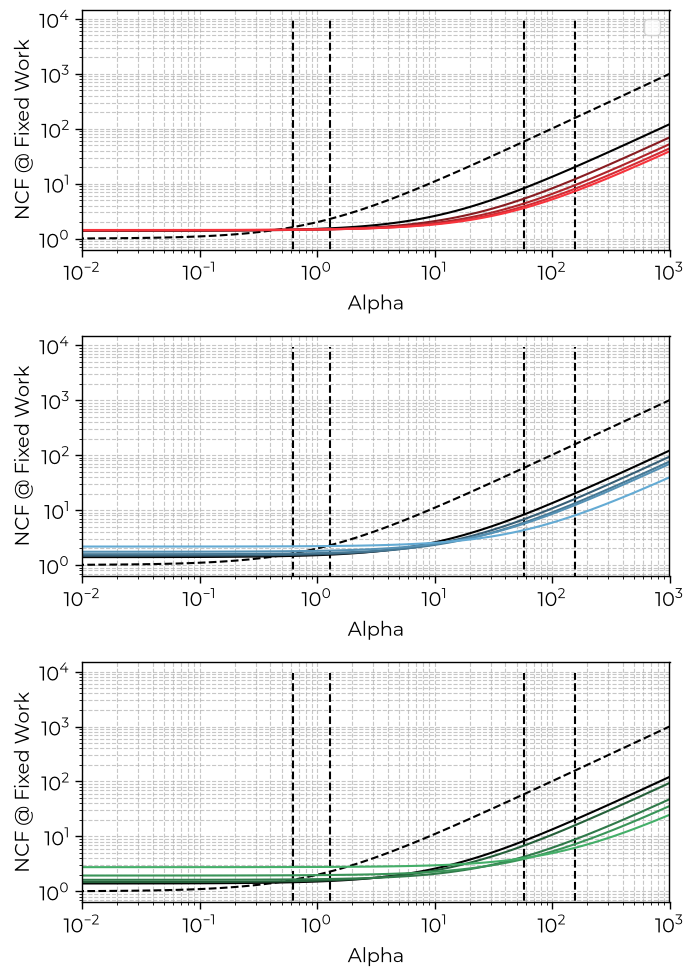

In [656]:
plot_soa = 0
plot_our = 0

# Plot the operation footprint vs FFT throughput
fig, ax = plt.subplots(3,1,figsize=(7.16, 10), sharey='row', squeeze=False)

for k in range(3):
    ax[k,0].set_xlabel('ALpha')
    ax[k,0].set_xlabel('ALpha')
    ax[k,0].grid(True, which='both', linestyle='--', alpha=0.7)
    ax[k,0].grid(True, which='both', linestyle='--', alpha=0.7)

    # Add our accelerator
    
    for i, alp in enumerate(array_alpha):
        p = ax[k,0].vlines(alp,ymin=0, ymax= np.max(theor_ncf_res),   color = 'black' , linestyle ='--')

    p = ax[k,0].plot(alpha_studied,  1+alpha_studied,   color = 'black' , linestyle ='--')

    for d, j in enumerate(analysis_Mem_type):
        p = ax[k,0].plot(alpha_studied,   theor_ncf_res[:,k,0,d,0],   color = 'black' , linestyle ='-')

    for i in range(1,arch_Dim):
        for d, j in enumerate(analysis_Mem_type):
            p = ax[k,0].plot(alpha_studied,   theor_ncf_res[:,k,i,d,0],   color = color_array[k,i] , linestyle ='-')

    #ax[k,0].hlines(y=1,xmin = 0, xmax=1, color= "black")
    ax[k,0].set_xlabel("Alpha")
    ax[k,0].set_xscale("log")
    ax[k,0].set_xlim([1e-2, np.max(alpha_studied)])
    #ax[k,0].set_yscale("log")
    ax[k,0].set_yscale("log")

    ax[k,0].set_ylabel("NCF @ Fixed Work")
ax[0,0].legend()

# Add legend
fig.tight_layout()
plt.show()



(15, 100)


C:\Users\maistriauxp\AppData\Local\Temp\ipykernel_29932\469925088.py:47: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax[0,0].legend()


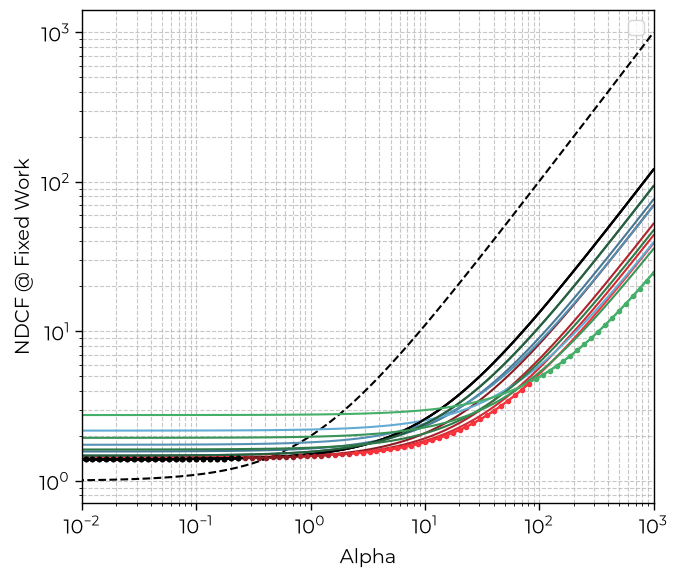

In [633]:
plot_soa = 1
plot_our = 0

# Plot the operation footprint vs FFT throughput
fig, ax = plt.subplots(1,1,figsize=(7, 6), sharey='row', squeeze=False)

curves = []
curve_colors = []

p = ax[0,0].plot(alpha_studied,  1+alpha_studied,   color = 'black' , linestyle ='--')

for k in range(3):
    ax[0,0].set_xlabel('ALpha')
    ax[0,0].grid(True, which='both', linestyle='--', alpha=0.7)

    # Add our accelerator

    #p = ax[0,0].plot(alpha_studied,  1+alpha_studied,   color = 'black' , linestyle ='--')
    for d, j in enumerate(analysis_Mem_type):
        p = ax[0,0].plot(alpha_studied, (  theor_ncf_res[:,k,0,d,0]),   color = 'black' , linestyle ='-')
        curves.append( theor_ncf_res[:,k,0,d,0])
        curve_colors.append('black')
        
    for i in range(1,arch_Dim):
        for d, j in enumerate(analysis_Mem_type):
            p = ax[0,0].plot(alpha_studied,   (theor_ncf_res[:,k,i,d,0]),   color = color_array[k,i] , linestyle ='-')
            curves.append(  theor_ncf_res[:,k,i,d,0])
            curve_colors.append(color_array[k,i])

# Highlight, at each x, the curve with the highest value there
curves = np.array(curves)
print(np.shape(curves))
min_values = np.min(curves, axis=0)
for curve, color in zip(curves, curve_colors):
    highlight = np.where(curve == min_values, curve, np.nan)
    ax[0,0].plot(alpha_studied, highlight, color=color, linestyle='-', marker = 'o',markersize=3) #, linewidth=6)

#ax[0,0].hlines(y=1,xmin = 0, xmax=1, color= "black")
ax[0,0].set_xscale("log")
#ax[0,0].set_yscale("log")
ax[0,0].set_yscale("log")
ax[0,0].set_xlim([1e-2, np.max(alpha_studied)])
ax[0,0].set_xlabel("Alpha")


ax[0,0].set_ylabel("NDCF @ Fixed Work")
ax[0,0].legend()

# Add legend
fig.tight_layout()
plt.show()



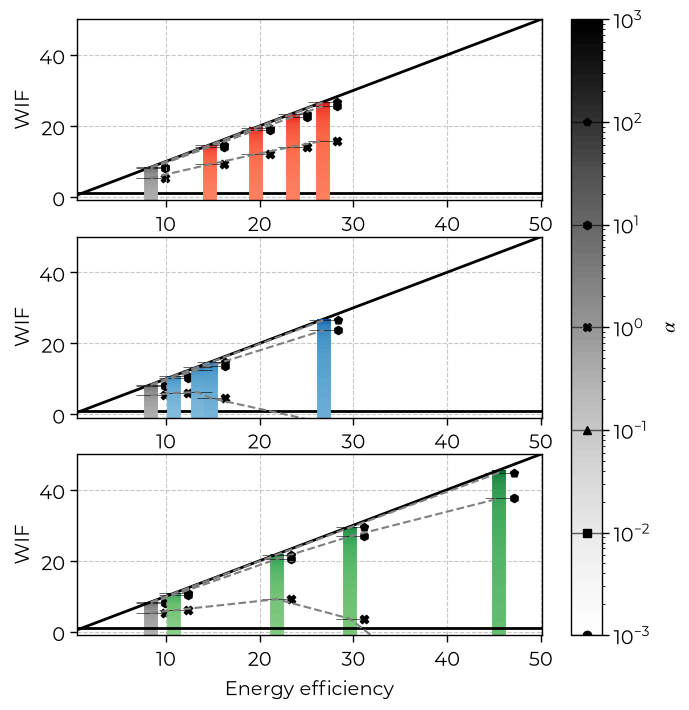

In [591]:

# -----------------

# ASI Framework separations
metric_space = np.linspace(0.5, 100, 100)


sep_strongly_sustainable = 1/metric_space
sep_weakly_sustainable   = 1/metric_space

sep_strongly_sustainable[np.where(sep_strongly_sustainable<1)] =1
sep_weakly_sustainable  [np.where(sep_weakly_sustainable>1)]   =1

arch_color_map = ['Reds', 'Blues', 'Greens']

alphaViolin=0.5
widthViolin=0.2
bwViolin   =0.01
# Plot the operation footprint vs FFT throughput

fig, ax = plt.subplots(3,1,figsize=(7.5*1, 8), squeeze=False)

metric =  (1/theor_energy_ratio[:,:arch_Dim,:]) 

metric_sust = theor_ncf_test[:,:,:arch_Dim,:] 


arch_color_map = ['Reds', 'Blues', 'Greens']

marker_list = ['o','s','^','X','h','p','*','<','+']



ax[-1,0].set_xlabel('Energy efficiency')

cmap = colormaps['Grays']
norm = matplotlib.colors.LogNorm(vmin=alpha_studied.min(), vmax=alpha_studied.max())

for k in range(3):
    ax[k,0].set_xscale('linear')
    ax[k,0].set_yscale('linear')
    ax[k,0].set_ylabel('WIF')
    ax[k,0].plot(metric_space, metric_space, 'black', linewidth=2, label='Strongly Sustainable')
    ax[k,0].plot(metric_space, np.ones(len(metric_space)), 'black', linewidth=2, label='Strongly Sustainable')
    try:
        ax[k,0].set_xlim([0.5,1.1*np.max(metric[:,:,analysis_Mem_type])])
    except:
        print("Limit Error")
    ax[k,0].set_ylim([-1 ,1.1*np.nanmax(metric_sust) ])#1.1*np.max(metric_sust)])
    ax[k,0].grid(True, which='both', linestyle='--', alpha=0.7)

 
    for d, j in enumerate(analysis_Mem_type):

        k = 2-k
        for i in range(0,arch_Dim):  

            points = np.array([metric[k,i,j]*np.ones((len(alpha_studied))),metric_sust[:,k,i,d]]).T.reshape(-1, 1, 2)
            segments = np.concatenate([points[:-1], points[1:]],axis=1)
            if i == 0 : 
                lc = LineCollection(segments, cmap=ListedColormap(mpl.colormaps["Grays"](np.linspace(0.0, 1, 100)))    ,norm=norm           ) #cmap = ListedColormap(mpl.colormaps["Grays"](np.linspace(0.2, 1, 100))))
            else:
                lc = LineCollection(segments, cmap=ListedColormap(mpl.colormaps[arch_color_map[k]](np.linspace(0.0, 1, 100)))  ,norm=norm               ) #cmap = ListedColormap(mpl.colormaps[arch_color_map[k]](np.linspace(0.2, 1, 100))))
            lc.set_array(alpha_studied)
            lc.set_linewidth(10)
            ax[k,0].add_collection(lc)



hline_w = np.max(metric)/30
for k in range(3):
    for d, j in enumerate(analysis_Mem_type):
        k = 2-k

        alpha_inv = np.arange(start=alpha_s_low, stop=alpha_s_high )
        for i_alp,alp in enumerate(alpha_inv):
            index = int(alpha_n*(alp-alpha_s_low)/(alpha_s_high-alpha_s_low))
            for i in range(0,arch_Dim):  
                ax[k,0].hlines (               metric_sust[index,k,i,d], xmin = metric[k,i,j]-hline_w, xmax=metric[k,i,j]+hline_w, linewidth=0.7, color='black', alpha=0.6)
                ax[k,0].scatter(metric[k,i,j]+hline_w, metric_sust[index,k,i,d], marker = marker_list [i_alp], color='black')

            ax[k,0].plot (metric[k,:,j], metric_sust[index,k,:,d], color='gray', linestyle ='--', alpha=1)
    

cbar = fig.colorbar(matplotlib.cm.ScalarMappable(cmap=ListedColormap(mpl.colormaps['Grays'](np.linspace(0.0, 1, 100))),norm=norm),ax=ax,orientation='vertical',label='Alpha')
cbar.set_label(r'$\alpha$')
for i_alp,alp in enumerate(np.arange(start=alpha_s_low, stop=alpha_s_high,step =1.00 )):
    index = int(alpha_n*(alp-alpha_s_low)/(alpha_s_high-alpha_s_low))
    cbar.ax.hlines(10**alp,xmin = -0.4, xmax=1, linewidth=1, color='black', alpha=0.6)
    cbar.ax.plot(0.5, 10**alp, marker = marker_list [i_alp], color='black')

# Add legend
plt.show()

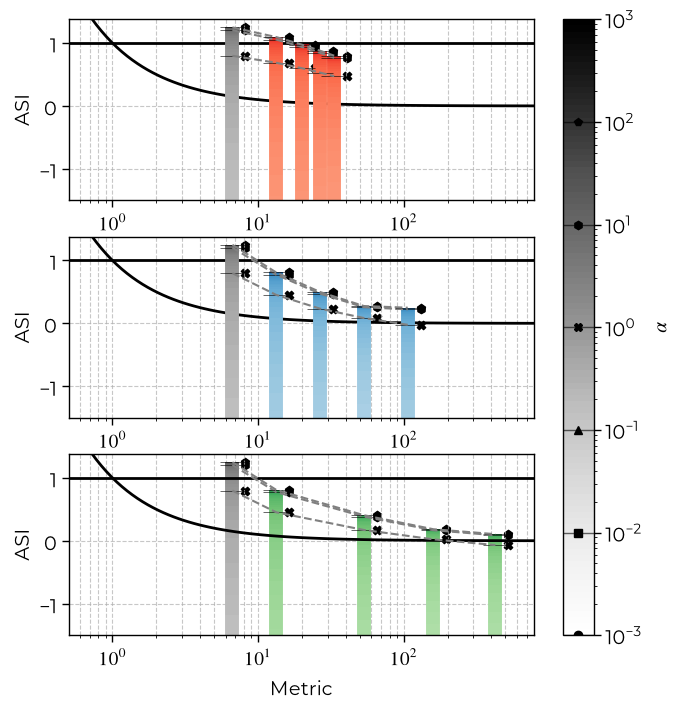

In [592]:

# -----------------


sep_strongly_sustainable[np.where(sep_strongly_sustainable<1)] =1
sep_weakly_sustainable  [np.where(sep_weakly_sustainable>1)]   =1

arch_color_map = ['Reds', 'Blues', 'Greens']

alphaViolin=0.5
widthViolin=0.2
bwViolin   =0.01
# Plot the operation footprint vs FFT throughput

fig, ax = plt.subplots(3,1,figsize=(7.5*1, 8), squeeze=False)

metric =  np.log10(theor_speedup_ratio[:,:arch_Dim,:])
metric_sust = (theor_asi_res[:,:,:arch_Dim,:]) 

arch_color_map = ['Reds', 'Blues', 'Greens']

marker_list = ['o','s','^','X','h','p','*','<','+']

s_log_min = -0.5
s_log_max = 3
metric_space = np.linspace(s_log_min, s_log_max, 100)

log_ticks = np.array([])
for i  in np.arange(np.floor(s_log_min), np.ceil(s_log_max),1) :
    log_ticks = np.append(log_ticks,i + np.log10(np.linspace(1,10, 10)))

formatter = FuncFormatter(lambda x_val, tick_pos: "$10^{{{:.0f}}}$".format(x_val))


cmap = colormaps['Grays']
norm = matplotlib.colors.LogNorm(vmin=alpha_studied.min(), vmax=alpha_studied.max())

for k in range(3):
    ax[k,0].set_xscale('linear')
    ax[k,0].set_yscale('linear')
    ax[k,0].set_ylabel('ASI')
    ax[k,0].plot(metric_space, 1/(10**metric_space), 'black', linewidth=2, label='Strongly Sustainable')
    ax[k,0].plot(metric_space, np.ones(len(metric_space)), 'black', linewidth=2, label='Strongly Sustainable')
    ax[k,0].set_xlabel('Metric')
    ax[k,0].set_xlim([-0.3,1.1*np.max(metric[:,:,analysis_Mem_type])])
    try :
        ax[k,0].set_ylim([-1.5 ,1.1*np.max(metric_sust) ])#1.1*np.max(metric_sust)])
    except:
        print("Limit issue")
        ax[k,0].set_ylim([-1.5 ,1.3 ])#1.1*np.max(metric_sust)])
    ax[k,0].grid(True, which='both', linestyle='--', alpha=0.7)
    ax[k,0].xaxis.set_major_locator(ticker.MultipleLocator(1))
    ax[k,0].xaxis.set_major_formatter(formatter)
    ax[k,0].xaxis.set_minor_locator(ticker.FixedLocator(log_ticks))

 
    for d, j in enumerate(analysis_Mem_type):

        k = 2-k
        for i in range(0,arch_Dim):  

            points = np.array([metric[k,i,j]*np.ones((len(alpha_studied))),metric_sust[:,k,i,d]]).T.reshape(-1, 1, 2)
            segments = np.concatenate([points[:-1], points[1:]],axis=1)
            if i == 0 : 
                lc = LineCollection(segments, cmap=ListedColormap(mpl.colormaps["Grays"](np.linspace(0.0, 1, 100)))    ,norm=norm           ) #cmap = ListedColormap(mpl.colormaps["Grays"](np.linspace(0.2, 1, 100))))
            else:
                lc = LineCollection(segments, cmap=ListedColormap(mpl.colormaps[arch_color_map[k]](np.linspace(0.0, 1, 100)))  ,norm=norm               ) #cmap = ListedColormap(mpl.colormaps[arch_color_map[k]](np.linspace(0.2, 1, 100))))
            lc.set_array(alpha_studied)
            lc.set_linewidth(10)
            ax[k,0].add_collection(lc)



hline_w = np.max(metric)/30
for k in range(3):
    for d, j in enumerate(analysis_Mem_type):
        k = 2-k

        alpha_inv = np.arange(start=alpha_s_low, stop=alpha_s_high )
        for i_alp,alp in enumerate(alpha_inv):
            index = int(alpha_n*(alp-alpha_s_low)/(alpha_s_high-alpha_s_low))
            for i in range(0,arch_Dim):  
                ax[k,0].hlines (               metric_sust[index,k,i,d], xmin = metric[k,i,j]-hline_w, xmax=metric[k,i,j]+hline_w, linewidth=0.7, color='black', alpha=0.6)
                ax[k,0].scatter(metric[k,i,j]+hline_w, metric_sust[index,k,i,d], marker = marker_list [i_alp], color='black')

            ax[k,0].plot (metric[k,:,j], metric_sust[index,k,:,d], color='gray', linestyle ='--', alpha=1)
    

cbar = fig.colorbar(matplotlib.cm.ScalarMappable(cmap=ListedColormap(mpl.colormaps['Grays'](np.linspace(0.0, 1, 100))),norm=norm),ax=ax,orientation='vertical',label='Alpha')
cbar.set_label(r'$\alpha$')
for i_alp,alp in enumerate(np.arange(start=alpha_s_low, stop=alpha_s_high,step =1.00 )):
    index = int(alpha_n*(alp-alpha_s_low)/(alpha_s_high-alpha_s_low))
    cbar.ax.hlines(10**alp,xmin = -0.4, xmax=1, linewidth=1, color='black', alpha=0.6)
    cbar.ax.plot(0.5, 10**alp, marker = marker_list [i_alp], color='black')

# Add legend
plt.show()
